#Predicting Phage-Host Interactions for Phage therapy


##Importing necessary libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay

## Data Preprocessing

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
datafile = '/content/drive/MyDrive/BME230AProject/Data/balanced_dataset.csv'
df = pd.read_csv(datafile)

In [4]:
num_features = df.shape[1]
num_instances = df.shape[0]

print("Number of features:", num_features)
print("Number of instances:", num_instances)

Number of features: 159
Number of instances: 5182


In [5]:
df.head()

,phage,host,interaction,A_avg_p,C_avg_p,D_avg_p,E_avg_p,F_avg_p,G_avg_p,H_avg_p,...,T_var_h,V_var_h,W_var_h,Y_var_h,MolW_var_h,C-_var_h,H-_var_h,O-_var_h,N-_var_h,S-_var_h
0,NC_019549,CP004005,1,0.212689,0.412340,0.387480,0.624800,0.276770,0.327964,0.638208,...,0.243642,0.268399,0.078394,0.195560,0.002332,0.002385,0.002289,0.002139,0.002075,0.011457
1,MG198776,CP004353,1,0.361878,0.303820,0.507009,0.708892,0.242235,0.410852,0.426868,...,0.303501,0.134439,0.125869,0.075507,0.002606,0.002620,0.002547,0.002579,0.002454,0.007215
2,NC_026586,HG530068,1,0.399470,0.332363,0.481483,0.505365,0.346104,0.501711,0.343765,...,0.317836,0.137922,0.230448,0.208919,0.001830,0.001844,0.001778,0.001691,0.001905,0.005199
3,NC_026587,HG530068,1,0.389363,0.362995,0.396089,0.594545,0.244299,0.489378,0.499877,...,0.317836,0.137922,0.230448,0.208919,0.001830,0.001844,0.001778,0.001691,0.001905,0.005199
4,NC_024071,NC_014574,1,0.130563,0.794535,0.219987,0.295521,0.666774,0.000000,0.721955,...,0.534263,0.153255,0.574622,0.285205,0.000668,0.000957,0.000671,0.000327,0.000106,0.044781


Convert strings into categorical data

In [6]:
# from sklearn.preprocessing import LabelEncoder

# phage_encoder = LabelEncoder()
# df['phage'] = phage_encoder.fit_transform(df['phage'])

# host_encoder = LabelEncoder()
# df['host'] = host_encoder.fit_transform(df['host'])

# df

## Splitting Data into Training, Validation and Test Sets

In [7]:
from sklearn.model_selection import train_test_split

classes = df['interaction']
data = df.drop(columns=['interaction', 'phage', 'host'])

temp_data, test_data, temp_classes, test_classes = train_test_split(data, classes, test_size=0.1, random_state=42)
train_data, validation_data, train_classes, validation_classes = train_test_split(temp_data, temp_classes, test_size=0.1, random_state=42)

print("Training set shape:", train_data.shape, train_classes.shape)
print("Validation set shape:", validation_data.shape, validation_classes.shape)
print("Test set shape:", test_data.shape, test_classes.shape)

Training set shape: (4196, 156) (4196,)
Validation set shape: (467, 156) (467,)
Test set shape: (519, 156) (519,)


In [8]:
train_data.head()

,A_avg_p,C_avg_p,D_avg_p,E_avg_p,F_avg_p,G_avg_p,H_avg_p,I_avg_p,K_avg_p,L_avg_p,...,T_var_h,V_var_h,W_var_h,Y_var_h,MolW_var_h,C-_var_h,H-_var_h,O-_var_h,N-_var_h,S-_var_h
4149,0.635627,0.201354,0.478137,0.436685,0.000000,0.602060,0.596320,0.247869,0.016029,0.215072,...,0.232885,0.103086,0.043076,0.470144,0.001608,0.001681,0.001550,0.001539,0.001245,0.007382
1287,0.305292,0.262738,0.353783,0.612919,0.291553,0.336519,0.414151,0.528702,0.613098,0.370181,...,0.287298,0.166411,0.098901,0.419312,0.001605,0.001626,0.001531,0.001515,0.001479,0.005164
2224,0.403914,0.255943,0.472505,0.600644,0.164355,0.568114,0.541493,0.343986,0.240781,0.225751,...,0.246354,0.146182,0.111740,0.036253,0.003060,0.003095,0.003009,0.002965,0.003007,0.006241
4230,0.401545,0.412445,0.507576,0.424772,0.142617,0.666544,0.653511,0.287398,0.188044,0.145980,...,0.260672,0.132071,0.078323,0.616171,0.004000,0.004083,0.003834,0.003982,0.003411,0.005201
3917,0.336521,0.503742,0.461192,0.558843,0.246619,0.493165,0.615653,0.373056,0.424458,0.152683,...,0.239868,0.101790,0.219045,0.272703,0.002548,0.002570,0.002502,0.002485,0.002367,0.006770


In [9]:
def validate_model(classes, predictions):
  accuracy = accuracy_score(classes, predictions)
  precision = precision_score(classes, predictions)
  recall = recall_score(classes, predictions)

  print("\nAccuracy:", accuracy)
  print("Precision:", precision)
  print("Recall:", recall)
  print("\n Confusion Matrix \n")

  cm = confusion_matrix(classes, predictions)
  ConfusionMatrixDisplay(confusion_matrix=cm).plot();

  TP = cm[0][0]
  FP = cm[0][1]
  FN = cm[1][0]
  TN = cm[1][1]

  print("True Positives=", TP)
  print("False Positives=", FP)
  print("True Negatives=", TN)
  print("False Negatives=", FN)

  return accuracy, precision, recall, cm


## Model 1: Random Forest Classification

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

# Create a RF classifier
random_forest_model = RandomForestClassifier()

#Parameter selection:
parameters = {'n_estimators': [100,200,300,400],
              'max_features': ['sqrt'],
               'max_depth': [1, 5, 10, 15, 20, 30],
               'bootstrap': [True],
               'criterion': ["gini"]}


# HyperParameter Tuning
tuning_forest_model = RandomizedSearchCV(random_forest_model, param_distributions = parameters, n_iter=5, cv=5)
tuning_forest_model.fit(train_data, train_classes)

print('Best hyperparameters:',  tuning_forest_model.best_params_)
print('Training Score:', tuning_forest_model.best_score_)
best_forest_model = tuning_forest_model.best_estimator_

Best hyperparameters: {'n_estimators': 100, 'max_features': 'sqrt', 'max_depth': 20, 'criterion': 'gini', 'bootstrap': True}
Training Score: 0.9945184176173448


###Validation

Validation Score: 0.9978586723768736

Accuracy: 0.9978586723768736
Precision: 0.9956331877729258
Recall: 1.0

 Confusion Matrix 

True Positives= 238
False Positives= 1
True Negatives= 228
False Negatives= 0


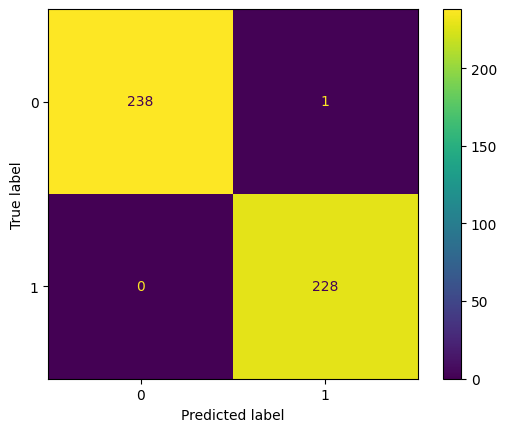

In [11]:
forest_validation_predictions = best_forest_model.predict(validation_data)

print('Validation Score:', best_forest_model.score(validation_data, validation_classes))
forest_accuracy, forest_precision, forest_recall, forest_cm = validate_model(validation_classes, forest_validation_predictions)

##Model 2: K-Nearest Neighbour

In [12]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

k_values = [i for i in range (2,30)]
scores = []

#Tuning the value of k
for k in k_values:
  knn_model = KNeighborsClassifier(n_neighbors=k)
  score = cross_val_score(knn_model, train_data, train_classes, cv=5)
  print("For k=", k, "the Training score is:", np.mean(score))
  scores.append(np.mean(score))

For k= 2 the Training score is: 0.9499511890572677
For k= 3 the Training score is: 0.9549588512401386
For k= 4 the Training score is: 0.9475685339690108
For k= 5 the Training score is: 0.9537641182814006
For k= 6 the Training score is: 0.9454228389806458
For k= 7 the Training score is: 0.948998524320336
For k= 8 the Training score is: 0.9418497077019126
For k= 9 the Training score is: 0.944947216073557
For k= 10 the Training score is: 0.9404205687042397
For k= 11 the Training score is: 0.9420880867245586
For k= 12 the Training score is: 0.9380367784777798
For k= 13 the Training score is: 0.9408964753958795
For k= 14 the Training score is: 0.9358919348430671
For k= 15 the Training score is: 0.9356541233895227
For k= 16 the Training score is: 0.930648731483058
For k= 17 the Training score is: 0.9316025313581928
For k= 18 the Training score is: 0.9285044554174471
For k= 19 the Training score is: 0.9313624496282422
For k= 20 the Training score is: 0.9287414155173392
For k= 21 the Training 

### Validation

In [13]:
#Choose best value of k
k = np.argmax(score)
best_knn_model = KNeighborsClassifier(n_neighbors=k)
best_knn_model.fit(train_data, train_classes)

KNeighborsClassifier(n_neighbors=3)

Training Score: 0.9783126787416587
Validation Score: 0.9507494646680942

Accuracy: 0.9507494646680942
Precision: 0.9638009049773756
Recall: 0.9342105263157895

 Confusion Matrix 

True Positives= 231
False Positives= 8
True Negatives= 213
False Negatives= 15


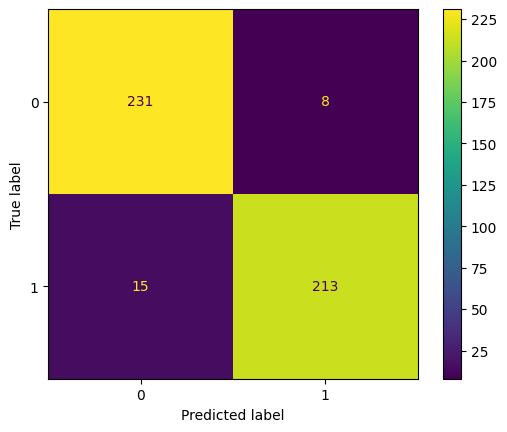

In [14]:
knn_validation_predictions = best_knn_model.predict(validation_data)

print('Training Score:', best_knn_model.score(train_data, train_classes))
print('Validation Score:', best_knn_model.score(validation_data, validation_classes))

knn_accuracy, knn_precision, knn_recall, knn_cm = validate_model(validation_classes, knn_validation_predictions)

##Model 3: Neural Network

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import StepLR

class Data(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X.astype(np.float32))
        self.y = torch.from_numpy(y.astype(np.float32))
        self.len = self.X.shape[0]

    def __getitem__(self, index):
        return self.X[index], self.y[index]

    def __len__(self):
        return self.len

loading data into pytorch tensors

In [16]:
batch_size = 32            #hyperparameter that can be tuned

train_dataset = Data(train_data.to_numpy(), train_classes.to_numpy())
train_dataloader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)

validation_dataset = Data(validation_data.to_numpy(), validation_classes.to_numpy())
validation_dataloader = DataLoader(dataset=validation_dataset, batch_size=batch_size, shuffle=True)

test_dataset = Data(test_data.to_numpy(), test_classes.to_numpy())
test_dataloader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=True)

In [17]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        # Perform initialization of the pytorch superclass
        super(NeuralNetwork, self).__init__()

        self.layer1 = nn.Linear(156, 128)
        self.layer2 = nn.Linear(128, 64)
        self.layer4 = nn.Linear(64, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = torch.relu(self.layer1(x))
        x = torch.relu(self.layer2(x))
        x = self.sigmoid(self.layer4(x))

        return x


The following are re-used from homework 3 since they are generic functions that we wrote for training a neural network. The model Architecture, loss functions, optimizers and hyper parameters are redefined based on the context of the problem.

In [18]:
def train_batch(model, x, y, optimizer, loss_fn):

    outputs = model.forward(x)
    y = y.view(-1, 1)
    loss = loss_fn(outputs, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss.data.item()

In [19]:
def train(model, loader, optimizer, scheduler, loss_fn, epochs):
    epoch_losses = list()

    for e in range(epochs):
        losses = list()
        for x, y in loader:
            loss = train_batch(model=model, x=x, y=y, optimizer=optimizer, loss_fn=loss_fn)
            losses.append(loss)
        epoch_losses.append(sum(losses)/len(losses))
        scheduler.step()

        print("Epoch: ", e+1)

    return epoch_losses

In [20]:
def test_batch(model, x, y):
    y_predict = model.forward(x)

    return y, y_predict

In [21]:
def test(model, loader):
    y_vectors = list()
    y_predict_vectors = list()

    batch_index = 0
    for x, y in loader:
        y, y_predict = test_batch(model=model, x=x, y=y)

        y_vectors.append(y.data.numpy())
        y_predict_vectors.append(y_predict.data.numpy())

        batch_index += 1

    y_predict_vector = np.concatenate(y_predict_vectors)
    y_vector = np.concatenate(y_vectors)

    return y_vector, y_predict_vector

In [22]:
def run(neural_network_model, train_dataloader, validation_dataloader, batch_size_train, n_epochs, learning_rate):

    # Initialize the optimizer with above parameters
    optimizer = optim.AdamW(neural_network_model.parameters(), lr=learning_rate)
    scheduler = StepLR(optimizer, step_size=5, gamma=0.1)  # Step Learning Rate Scheduler

    # Define the loss function
    loss_fn = nn.BCELoss()

    # Train and get the resulting loss per iteration
    loss = train(model=neural_network_model, loader=train_dataloader, optimizer=optimizer, scheduler=scheduler, loss_fn=loss_fn, epochs=n_epochs)

    # Test and get the resulting predicted y values
    train_labels, train_probabilities = test(model=neural_network_model, loader=train_dataloader)

    return loss, train_labels, train_probabilities

In [33]:
learning_rate = 3e-3   #hyperparameter that can be tuned
n_epochs = 30         #hyperparameter that can be tuned

neural_network_model =  NeuralNetwork()
losses, nn_train_labels, nn_train_probabilities = run(neural_network_model, train_dataloader, validation_dataloader, batch_size, n_epochs, learning_rate)

print(losses)

Epoch:  1
Epoch:  2
Epoch:  3
Epoch:  4
Epoch:  5
Epoch:  6
Epoch:  7
Epoch:  8
Epoch:  9
Epoch:  10
Epoch:  11
Epoch:  12
Epoch:  13
Epoch:  14
Epoch:  15
Epoch:  16
Epoch:  17
Epoch:  18
Epoch:  19
Epoch:  20
Epoch:  21
Epoch:  22
Epoch:  23
Epoch:  24
Epoch:  25
Epoch:  26
Epoch:  27
Epoch:  28
Epoch:  29
Epoch:  30
[0.4966925330685847, 0.3609987525551608, 0.32548906484788115, 0.2665316874556469, 0.23817436464808203, 0.1972622781088858, 0.19391095739873973, 0.18404017332376857, 0.1774350808171386, 0.1749649139572725, 0.1695906539080721, 0.16747285944945883, 0.16907370804498592, 0.16712860788472675, 0.1665180128801501, 0.16592215238647026, 0.16610505386735452, 0.16674264142233314, 0.1652453210077841, 0.1657079096714204, 0.17167286222066844, 0.16589702304565546, 0.1652879643846642, 0.16518926748893026, 0.16502051759214903, 0.16574799768965354, 0.16499821734826334, 0.165733754140974, 0.16506737154541593, 0.1651613024402071]


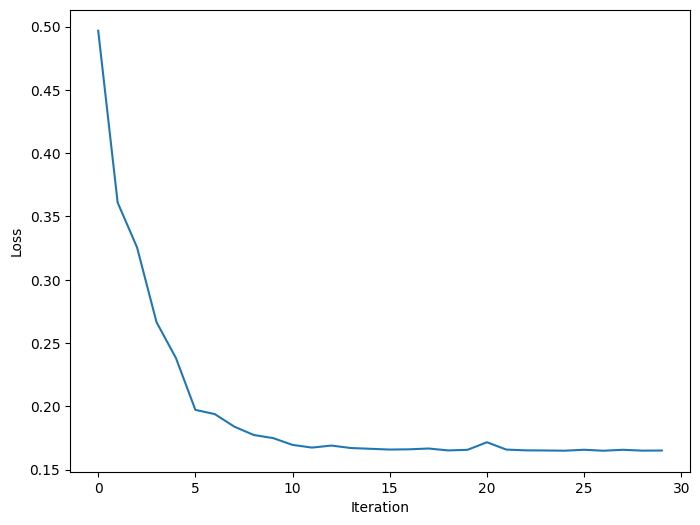

In [34]:
def plot_loss(losses):
    fig = pyplot.gcf()
    fig.set_size_inches(8,6)
    ax = pyplot.axes()
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Loss")
    x_loss = list(range(len(losses)))
    pyplot.plot(x_loss, losses)
    pyplot.show()
    pyplot.close()

plot_loss(losses)

In [35]:
nn_train_predictions = ((nn_train_probabilities >= 0.5).astype(int)).flatten()
nn_train_accuracy = accuracy_score(nn_train_labels, nn_train_predictions)
print("Training Score", nn_train_accuracy)

Training Score 0.9356530028598665


In [26]:
learning_rates = [5e-3, 3e-3, 1e-3, 5e-4, 3e-4, 1e-4, 6e-5, 5e-5, 4e-5]
num_epochs = [10, 15, 20, 30, 35]
training_scores = []
parameters = []

for lr in learning_rates:
  for n in num_epochs:
    neural_network_model =  NeuralNetwork()
    losses, nn_train_labels, nn_train_probabilities = run(neural_network_model, train_dataloader, validation_dataloader, batch_size, n, lr)
    nn_train_predictions = ((nn_train_probabilities > 0.5).astype(int)).flatten()
    nn_train_accuracy = accuracy_score(nn_train_labels, nn_train_predictions)
    print("Training Score", nn_train_accuracy)
    training_scores.append(nn_train_accuracy)
    parameters.append((lr, n))


Epoch:  1
Epoch:  2
Epoch:  3
Epoch:  4
Epoch:  5
Epoch:  6
Epoch:  7
Epoch:  8
Epoch:  9
Epoch:  10
Training Score 0.9239752144899904
Epoch:  1
Epoch:  2
Epoch:  3
Epoch:  4
Epoch:  5
Epoch:  6
Epoch:  7
Epoch:  8
Epoch:  9
Epoch:  10
Epoch:  11
Epoch:  12
Epoch:  13
Epoch:  14
Epoch:  15
Training Score 0.9280266920877026
Epoch:  1
Epoch:  2
Epoch:  3
Epoch:  4
Epoch:  5
Epoch:  6
Epoch:  7
Epoch:  8
Epoch:  9
Epoch:  10
Epoch:  11
Epoch:  12
Epoch:  13
Epoch:  14
Epoch:  15
Epoch:  16
Epoch:  17
Epoch:  18
Epoch:  19
Epoch:  20
Training Score 0.9375595805529076
Epoch:  1
Epoch:  2
Epoch:  3
Epoch:  4
Epoch:  5
Epoch:  6
Epoch:  7
Epoch:  8
Epoch:  9
Epoch:  10
Epoch:  11
Epoch:  12
Epoch:  13
Epoch:  14
Epoch:  15
Epoch:  16
Epoch:  17
Epoch:  18
Epoch:  19
Epoch:  20
Epoch:  21
Epoch:  22
Epoch:  23
Epoch:  24
Epoch:  25
Epoch:  26
Epoch:  27
Epoch:  28
Epoch:  29
Epoch:  30
Training Score 0.919208770257388
Epoch:  1
Epoch:  2
Epoch:  3
Epoch:  4
Epoch:  5
Epoch:  6
Epoch:  7
Epoch:

In [27]:
for i in range(len(training_scores)):
  print("For learning_rate=", parameters[i][0], "and epoch=", parameters[i][1], "training_score=", training_scores[i])


best_parameters = parameters[np.argmax(training_scores)]
print(best_parameters)

For learning_rate= 0.005 and epoch= 10 training_score= 0.9239752144899904
For learning_rate= 0.005 and epoch= 15 training_score= 0.9280266920877026
For learning_rate= 0.005 and epoch= 20 training_score= 0.9375595805529076
For learning_rate= 0.005 and epoch= 30 training_score= 0.919208770257388
For learning_rate= 0.005 and epoch= 35 training_score= 0.932793136320305
For learning_rate= 0.003 and epoch= 10 training_score= 0.9242135367016205
For learning_rate= 0.003 and epoch= 15 training_score= 0.9299332697807435
For learning_rate= 0.003 and epoch= 20 training_score= 0.928741658722593
For learning_rate= 0.003 and epoch= 30 training_score= 0.902049571020019
For learning_rate= 0.003 and epoch= 35 training_score= 0.9316015252621545
For learning_rate= 0.001 and epoch= 10 training_score= 0.9072926596758818
For learning_rate= 0.001 and epoch= 15 training_score= 0.9006196377502383
For learning_rate= 0.001 and epoch= 20 training_score= 0.909437559580553
For learning_rate= 0.001 and epoch= 30 trai

Validation

In [36]:
nn_validation_labels, nn_validation_probabilities = test(model=neural_network_model, loader=validation_dataloader)
nn_validation_predictions = ((nn_validation_probabilities > 0.5).astype(int)).flatten()
nn_validation_accuracy = accuracy_score(nn_validation_labels, nn_validation_predictions)
print("Validation Score", nn_validation_accuracy)

Validation Score 0.9164882226980728


## Evaluation and Comparison of Models

Final testing on the unseen test data

Random Forest:

test Score: 0.9961464354527938

Accuracy: 0.9961464354527938
Precision: 0.9961538461538462
Recall: 0.9961538461538462

 Confusion Matrix 

True Positives= 258
False Positives= 1
True Negatives= 259
False Negatives= 1


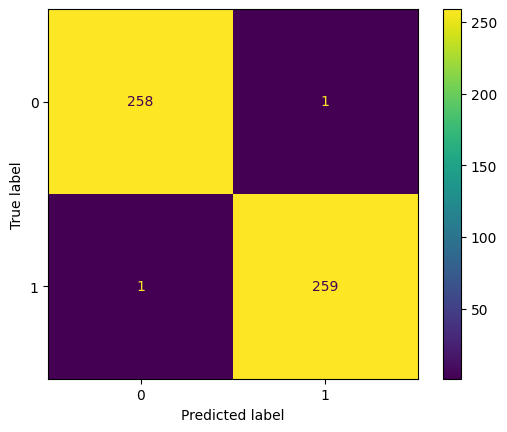

In [29]:
forest_test_predictions = best_forest_model.predict(test_data)

print('test Score:', best_forest_model.score(test_data, test_classes))
forest_test_accuracy, forest_test_precision, forest_test_recall, forest_test_cm = validate_model(test_classes, forest_test_predictions)

KNN


Accuracy: 0.9595375722543352
Precision: 0.9613899613899614
Recall: 0.9576923076923077

 Confusion Matrix 

True Positives= 249
False Positives= 10
True Negatives= 249
False Negatives= 11


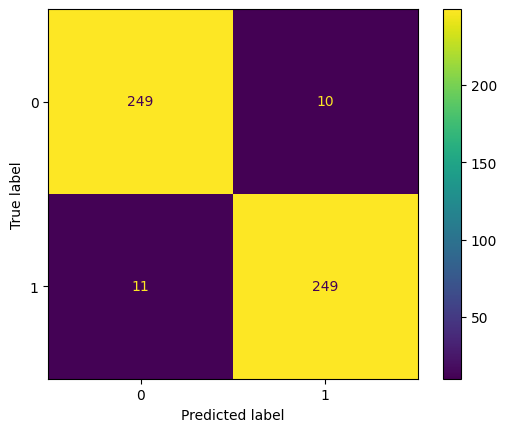

In [30]:
knn_test_predictions = best_knn_model.predict(test_data)

knn_test_accuracy, knn_test_precision, knn_test_recall, knn_test_cm = validate_model(test_classes, knn_test_predictions)

Neural Network

In [37]:
nn_test_labels, nn_test_probabilities = test(model=neural_network_model, loader=test_dataloader)
nn_test_predictions = ((nn_test_probabilities > 0.5).astype(int)).flatten()
nn_test_accuracy = accuracy_score(nn_test_labels, nn_test_predictions)
print("Test Score", nn_test_accuracy)

Test Score 0.928709055876686



Accuracy: 0.928709055876686
Precision: 0.9239543726235742
Recall: 0.9346153846153846

 Confusion Matrix 

True Positives= 239
False Positives= 20
True Negatives= 243
False Negatives= 17


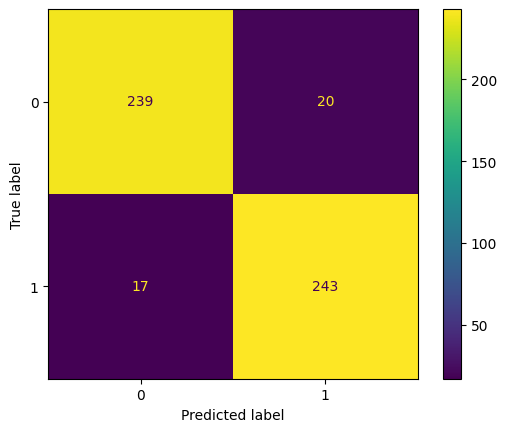

In [38]:
nn_test_accuracy, nn_test_precision, nn_test_recall, nn_test_cm = validate_model(nn_test_labels, nn_test_predictions)